In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import time
from PIL import Image, ImageOps
import numpy as np

print("Tüm araçlar ve kütüphaneler başarıyla yüklendi!")

Tüm araçlar ve kütüphaneler başarıyla yüklendi!


In [2]:
# Resimleri yapay zekanın anlayacağı matris formatına çeviriyoruz
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)) # Standart sayısal dengeleme
])

# MNIST veri setini internetten indiriyoruz
full_train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# Eğitim verisini Train (%83.3) ve Validation (%16.7) olarak bölüyoruz
train_dataset, val_dataset = random_split(full_train_dataset, [50000, 10000])

# Verileri 64'erli paketler (batch) halinde okumak için hazırlıyoruz
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print(f"Eğitim Verisi Sayısı: {len(train_dataset)}")
print(f"Doğrulama Verisi Sayısı: {len(val_dataset)}")
print(f"Test Verisi Sayısı: {len(test_dataset)}")

100%|██████████| 9.91M/9.91M [00:00<00:00, 36.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.00MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.99MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.53MB/s]

Eğitim Verisi Sayısı: 50000
Doğrulama Verisi Sayısı: 10000
Test Verisi Sayısı: 10000


In [3]:
class MLPModel(nn.Module):
    def __init__(self):
        super(MLPModel, self).__init__()
        # 28x28 boyutundaki kare resmi düzleştirip 784 elemanlı vektör yapar
        self.flatten = nn.Flatten()

        # Katmanların sırayla bağlanması
        self.network = nn.Sequential(
            nn.Linear(784, 256),  # 1. Gizli Katman
            nn.ReLU(),             # Aktivasyon fonksiyonu (ödev şartı)
            nn.Linear(256, 128),  # 2. Gizli Katman
            nn.ReLU(),             # Aktivasyon fonksiyonu
            nn.Linear(128, 10)    # Çıkış katmanı (0-9 arası 10 sınıf)
        )

    def forward(self, x):
        x = self.flatten(x)
        return self.network(x)

model = MLPModel()
print("MLP Modeli başarıyla oluşturuldu:")
print(model)

MLP Modeli başarıyla oluşturuldu:
MLPModel(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (network): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [4]:
criterion = nn.CrossEntropyLoss() # Sınıflandırma hata fonksiyonu
optimizer = optim.Adam(model.parameters(), lr=0.001) # Öğrenme algoritması

epochs = 15
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

start_time = time.time() # Zamanlayıcıyı başlat

for epoch in range(epochs):
    # --- EĞİTİM (TRAINING) ---
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0

    for images, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)

    epoch_train_loss = train_loss / train_total
    epoch_train_acc = train_correct / train_total

    # --- DOĞRULAMA (VALIDATION) ---
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    epoch_val_loss = val_loss / val_total
    epoch_val_acc = val_correct / val_total

    # Değerleri rapora eklemek üzere kaydediyoruz
    history['train_loss'].append(epoch_train_loss)
    history['val_loss'].append(epoch_val_loss)
    history['train_acc'].append(epoch_train_acc)
    history['val_acc'].append(epoch_val_acc)

    print(f"Tur (Epoch) {epoch+1:02d}/{epochs} | "
          f"Eğitim Hata: {epoch_train_loss:.4f} Başarı: %{epoch_train_acc*100:.2f} | "
          f"Doğrulama Hata: {epoch_val_loss:.4f} Başarı: %{epoch_val_acc*100:.2f}")

end_time = time.time()
total_time = end_time - start_time
print(f"\n Toplam Eğitim Süresi: {total_time:.2f} saniye")

Tur (Epoch) 01/15 | Eğitim Hata: 0.2480 Başarı: %92.48 | Doğrulama Hata: 0.1584 Başarı: %95.16
Tur (Epoch) 02/15 | Eğitim Hata: 0.1000 Başarı: %96.89 | Doğrulama Hata: 0.1048 Başarı: %96.78
Tur (Epoch) 03/15 | Eğitim Hata: 0.0673 Başarı: %97.86 | Doğrulama Hata: 0.1139 Başarı: %96.58
Tur (Epoch) 04/15 | Eğitim Hata: 0.0508 Başarı: %98.32 | Doğrulama Hata: 0.0987 Başarı: %97.18
Tur (Epoch) 05/15 | Eğitim Hata: 0.0397 Başarı: %98.67 | Doğrulama Hata: 0.1026 Başarı: %97.23
Tur (Epoch) 06/15 | Eğitim Hata: 0.0318 Başarı: %98.92 | Doğrulama Hata: 0.1072 Başarı: %97.25
Tur (Epoch) 07/15 | Eğitim Hata: 0.0296 Başarı: %99.00 | Doğrulama Hata: 0.1011 Başarı: %97.48
Tur (Epoch) 08/15 | Eğitim Hata: 0.0211 Başarı: %99.28 | Doğrulama Hata: 0.1223 Başarı: %97.19
Tur (Epoch) 09/15 | Eğitim Hata: 0.0230 Başarı: %99.17 | Doğrulama Hata: 0.1147 Başarı: %97.31
Tur (Epoch) 10/15 | Eğitim Hata: 0.0194 Başarı: %99.36 | Doğrulama Hata: 0.1449 Başarı: %97.03
Tur (Epoch) 11/15 | Eğitim Hata: 0.0186 Başarı: %9


 NİHAİ TEST BAŞARISI (Test Accuracy): %97.86



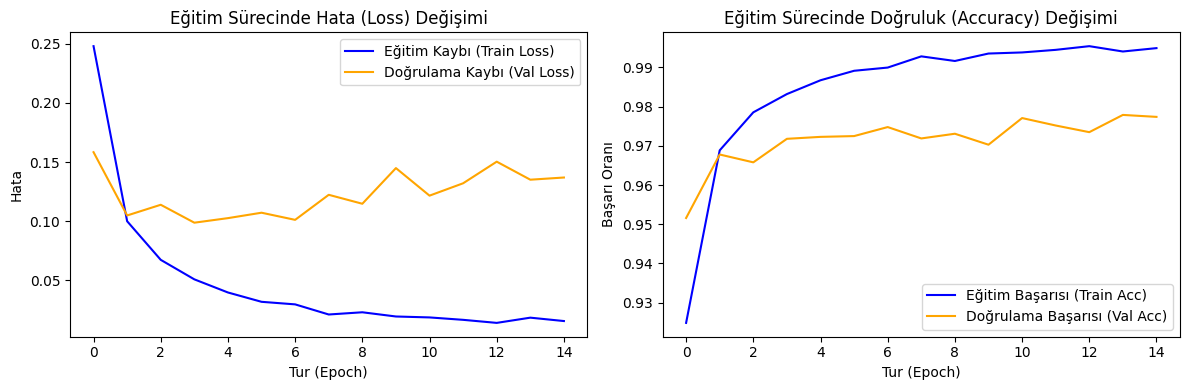

In [5]:
# 1. Test Başarısını Ölçme
model.eval()
test_correct, test_total = 0, 0
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        test_correct += (preds == labels).sum().item()
        test_total += labels.size(0)

test_acc = (test_correct / test_total) * 100
print(f"\n NİHAİ TEST BAŞARISI (Test Accuracy): %{test_acc:.2f}\n")

# 2. Loss ve Accuracy Grafiklerini Çizdirme
plt.figure(figsize=(12, 4))

# Hata (Loss) Grafiği
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Eğitim Kaybı (Train Loss)', color='blue')
plt.plot(history['val_loss'], label='Doğrulama Kaybı (Val Loss)', color='orange')
plt.title('Eğitim Sürecinde Hata (Loss) Değişimi')
plt.xlabel('Tur (Epoch)')
plt.ylabel('Hata')
plt.legend()

# Doğruluk (Accuracy) Grafiği
plt.subplot(1, 2, 2)
plt.plot(history['train_acc'], label='Eğitim Başarısı (Train Acc)', color='blue')
plt.plot(history['val_acc'], label='Doğrulama Başarısı (Val Acc)', color='orange')
plt.title('Eğitim Sürecinde Doğruluk (Accuracy) Değişimi')
plt.xlabel('Tur (Epoch)')
plt.ylabel('Başarı Oranı')
plt.legend()

plt.tight_layout()
plt.show()

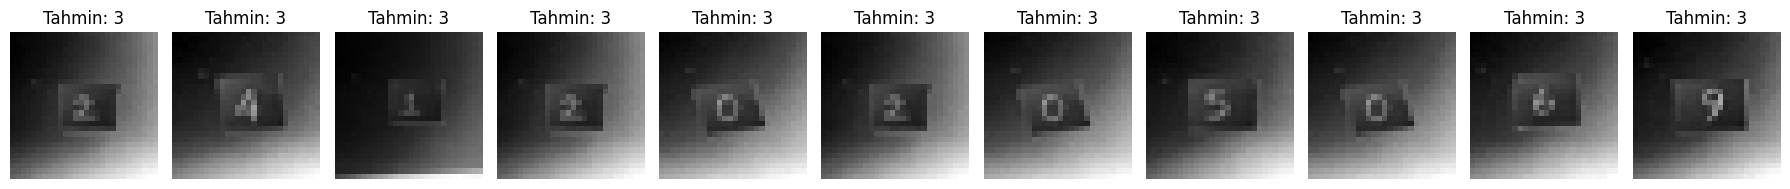

In [7]:
def preprocess_custom_image(image_path):
    # 1. Resmi aç ve Siyah-Beyaz (Grayscale) yap
    img = Image.open(image_path).convert('L')

    # 2. Kağıt beyaz, yazı siyahsa tersine çevir (MNIST siyah arka plan ister)
    if np.mean(img) > 127:
        img = ImageOps.invert(img)

    # 3. 28x28 boyutuna getir
    img = img.resize((28, 28))

    # 4. Tensor dönüştürme ve normalizasyon
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.1307,), (0.3081,))
    ])

    tensor_img = transform(img).unsqueeze(0)
    return tensor_img, img

# OKUL NUMARAN: 24120205069
# Dosya uzantıları ve isimleri mevcut dosyalara göre (.jpeg olarak) güncellendi
my_student_id_images = [
    'rakam2.jpeg', # 2
    'rakam4jpeg.jpeg', # 4
    'rakam1.jpeg', # 1
    'rakam2.jpeg', # 2
    'rakam0.jpeg', # 0
    'rakam2.jpeg', # 2
    'rakam0.jpeg', # 0
    'rakam5.jpeg', # 5
    'rakam0.jpeg', # 0
    'rakam6.jpeg', # 6
    'rakam9.jpeg'  # 9
]

model.eval()
plt.figure(figsize=(18, 4))

for idx, img_path in enumerate(my_student_id_images):
    tensor_img, original_img = preprocess_custom_image(img_path)

    with torch.no_grad():
        output = model(tensor_img)
        prediction = torch.argmax(output, dim=1).item()

    plt.subplot(1, len(my_student_id_images), idx + 1)
    plt.imshow(original_img, cmap='gray')
    plt.title(f"Tahmin: {prediction}", fontsize=12)
    plt.axis('off')

plt.tight_layout()
plt.show()